# Lab 5 VAE Experiment 1: Fashion MNIST with latent_dim = 2

This notebook modifies the original MNIST VAE code to use the Fashion MNIST dataset instead. The aim is to test whether two latent neurons are enough to generate and represent Fashion MNIST images.

# 1. Control GPU memory usage.

In [8]:
import tensorflow as tf
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# 2. Import libraries

In [9]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import tensorflow as tf
import keras
from keras import layers

# 3. Sampling Layer

## This is to generate values according to the standard normal distribution, for neurons in the latent layer.

The Sampling layer creates the latent vector `z` using `z_mean` and `z_log_var`. This allows the VAE to learn a smooth latent space and generate new images from sampled latent values.


In [10]:
class Sampling(layers.Layer):
    """Uses (z_mean, z_log_var) to sample z, the vector encoding a digit."""

    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# 4. Build Encoder with latent_dim = 2

In this experiment, `latent_dim = 2`. This means each Fashion MNIST image is compressed into only two latent values. This allows the latent space to be visualised easily using `z[0]` and `z[1]`.

In [11]:
latent_dim = 2 # This is the place to specify how many latent neurons want in VAE.

encoder_inputs = keras.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(encoder_inputs)
x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Flatten()(x)
x = layers.Dense(16, activation="relu")(x)
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])
encoder = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

Model: "encoder"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 28, 28, 1)]  0           []                               
                                                                                                  
 conv2d (Conv2D)                (None, 14, 14, 32)   320         ['input_1[0][0]']                
                                                                                                  
 conv2d_1 (Conv2D)              (None, 7, 7, 64)     18496       ['conv2d[0][0]']                 
                                                                                                  
 flatten (Flatten)              (None, 3136)         0           ['conv2d_1[0][0]']               
                                                                                            

# 5. Build Decoder

The decoder takes the 2-dimensional latent vector and reconstructs it into a 28 × 28 grayscale Fashion MNIST image.

In [12]:
latent_inputs = keras.Input(shape=(latent_dim,))
x = layers.Dense(7 * 7 * 64, activation="relu")(latent_inputs)
x = layers.Reshape((7, 7, 64))(x)
x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same")(x)
decoder_outputs = layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")(x)
decoder = keras.Model(latent_inputs, decoder_outputs, name="decoder")
decoder.summary()

Model: "decoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 2)]               0         
                                                                 
 dense_1 (Dense)             (None, 3136)              9408      
                                                                 
 reshape (Reshape)           (None, 7, 7, 64)          0         
                                                                 
 conv2d_transpose (Conv2DTra  (None, 14, 14, 64)       36928     
 nspose)                                                         
                                                                 
 conv2d_transpose_1 (Conv2DT  (None, 28, 28, 32)       18464     
 ranspose)                                                       
                                                                 
 conv2d_transpose_2 (Conv2DT  (None, 28, 28, 1)        289 

# 6. Build VAE Model
## This part of the code defines a VAE object (as a class), and the training process.

The VAE combines the encoder and decoder. It is trained using reconstruction loss and KL loss. Reconstruction loss measures how well the image is reconstructed, while KL loss regularises the latent space.

In [13]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    keras.losses.binary_crossentropy(data, reconstruction),
                    axis=(1, 2),
                )
            )
            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
            total_loss = reconstruction_loss + kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

## Original Fashion MNIST Dataset Overview

Before training the VAE, real Fashion MNIST samples are displayed. This gives a reference point for comparing the generated images later.

Instead of only showing the first few images, two examples from each class are shown so that all 10 Fashion MNIST categories are represented.

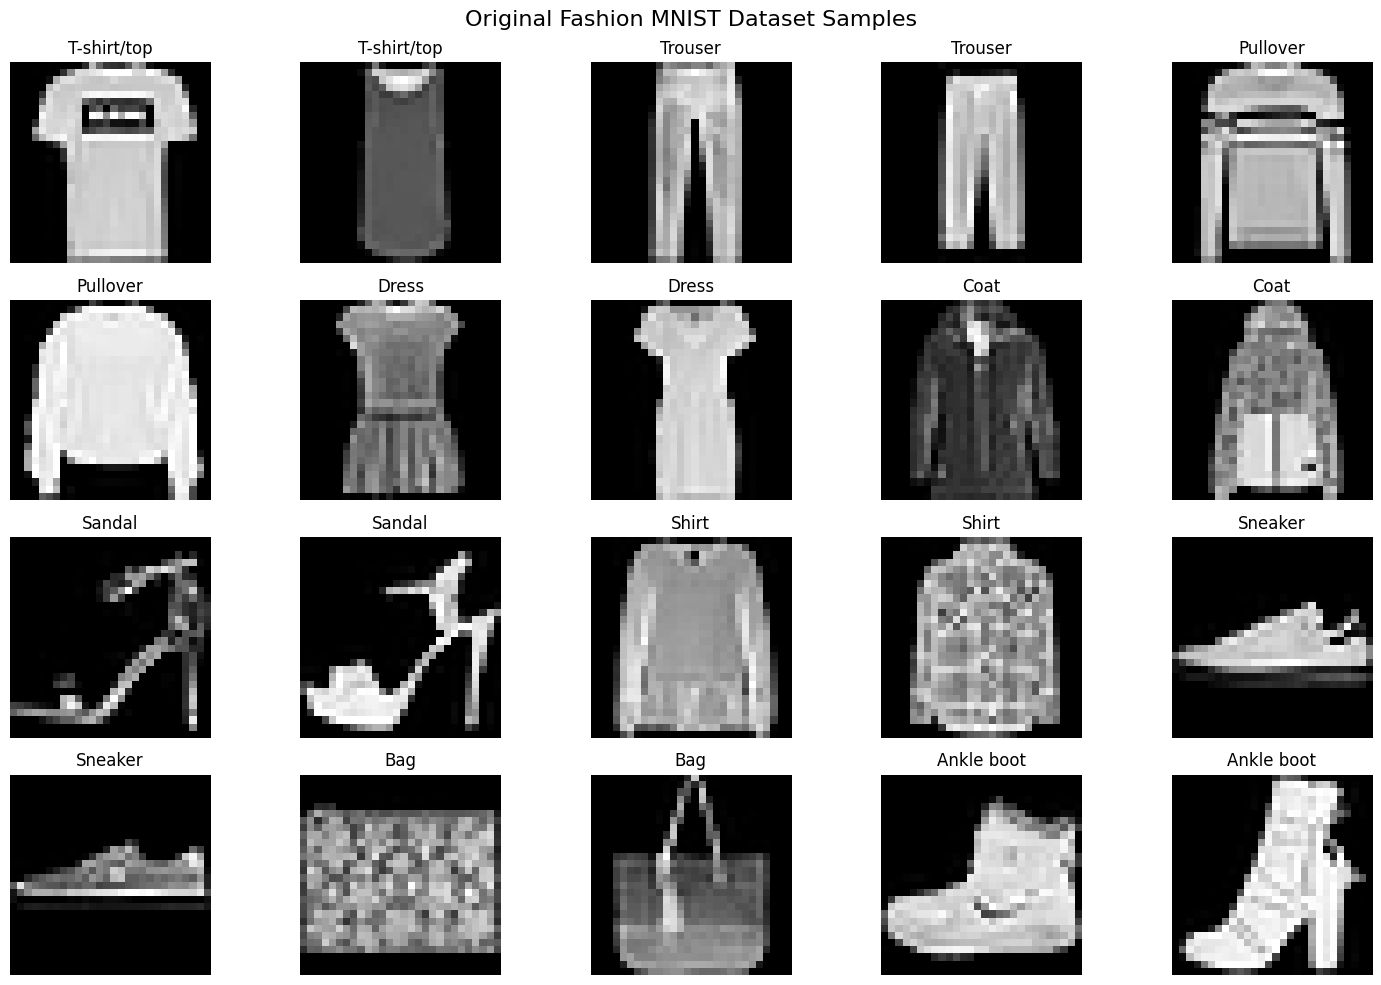

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Load Fashion MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

fashion_class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

# Show multiple real examples from the dataset
plt.figure(figsize=(15, 10))

plot_index = 1

# Show 2 examples per class = 20 images
for class_id in range(10):
    class_indices = np.where(y_train == class_id)[0][:2]

    for idx in class_indices:
        plt.subplot(4, 5, plot_index)
        plt.imshow(x_train[idx], cmap="gray")
        plt.title(fashion_class_names[class_id])
        plt.axis("off")
        plot_index += 1

plt.suptitle("Original Fashion MNIST Dataset Samples", fontsize=16)
plt.tight_layout()
plt.show()

### Dataset Observation

The original Fashion MNIST dataset contains 10 fashion categories. Some classes, such as T-shirt/top, Pullover, Coat, and Shirt, are visually similar because they are all upper-body clothing. This explains why these classes may overlap in the VAE latent space and why some generated images are harder to distinguish clearly.

# 7. Train VAE on Fashion MNIST

The Fashion MNIST training and test images are combined to form a dataset of 70,000 images for unsupervised VAE training.

The images are reshaped to `(28, 28, 1)` and normalised from pixel values of 0–255 to the range `[0, 1]`.

Following the generative-modelling setup used in the VAE example, all available images are used to learn the data distribution. Therefore, the reported losses are training reconstruction metrics and should not be interpreted as unseen test-set performance.

In [15]:
# Prepare Fashion MNIST data for VAE training
fashion_digits = np.concatenate([x_train, x_test], axis=0)
fashion_digits = np.expand_dims(fashion_digits, -1).astype("float32") / 255

vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam())
vae.fit(fashion_digits, epochs=30, batch_size=128)

### Training Observation

The VAE was trained on Fashion MNIST for 30 epochs using `latent_dim = 2`. The total loss decreased from 374.0452 in epoch 1 to 261.8006 in epoch 30. The reconstruction loss also decreased from 315.6041 to 255.0941, showing that the model learned to reconstruct Fashion MNIST images better over time.

# 8. Generate Fashion MNIST Images from Latent Space

The function below generates Fashion MNIST-like images by varying `z[0]` and `z[1]` across the latent space.

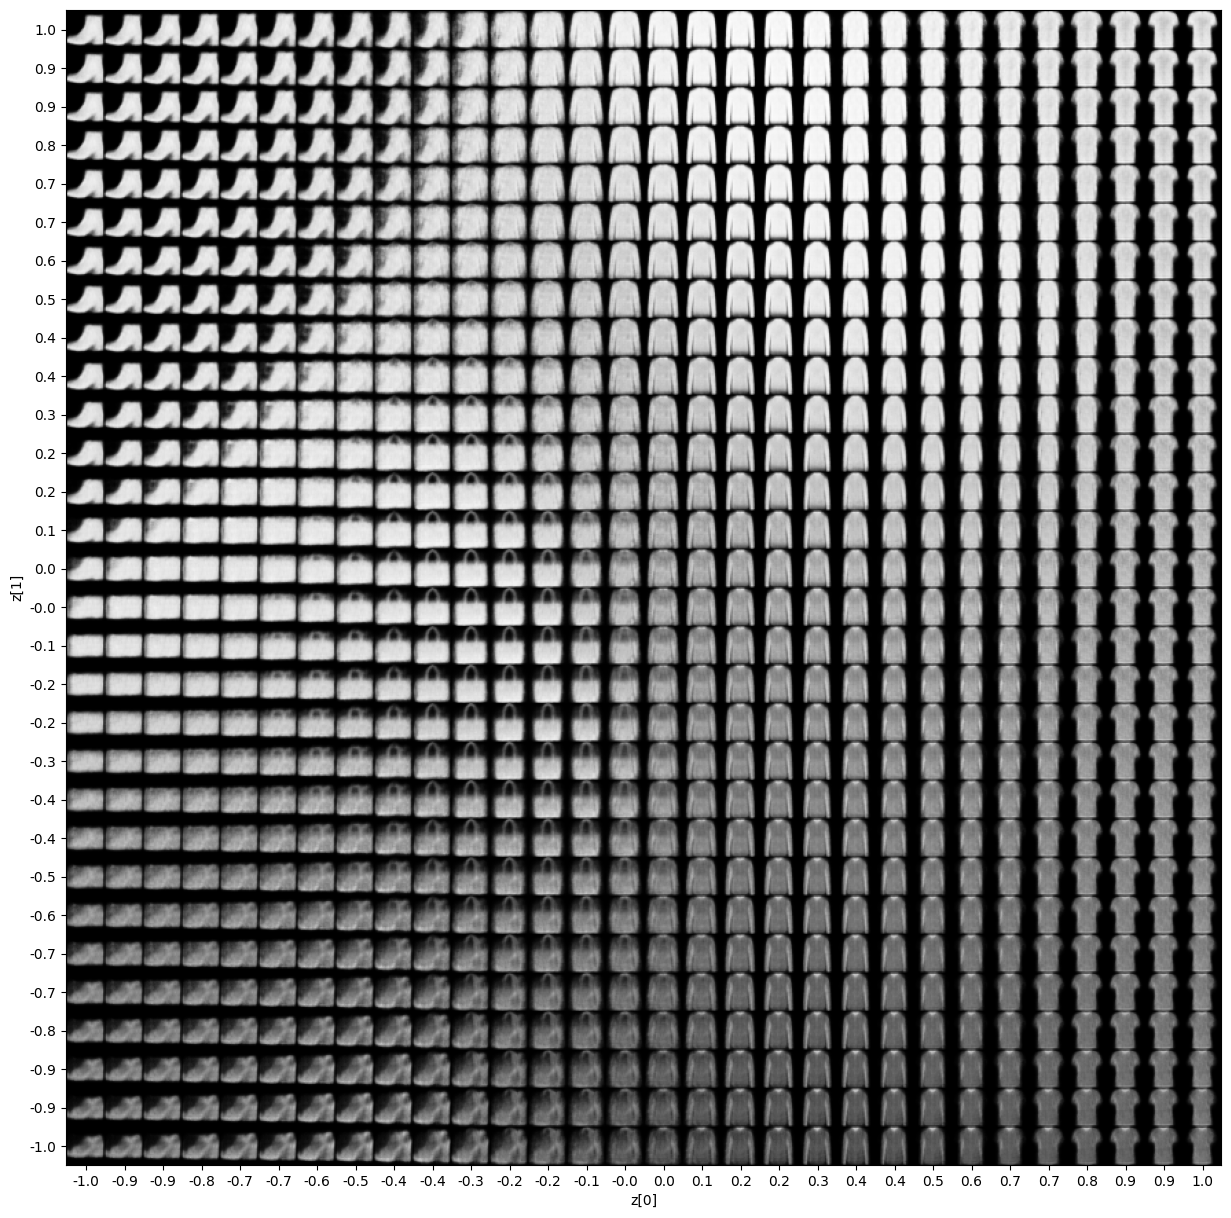

In [16]:
import matplotlib.pyplot as plt


def plot_latent_space(vae, n=30, figsize=15):
    # display a n*n 2D manifold of digits
    digit_size = 28
    scale = 1.0
    figure = np.zeros((digit_size * n, digit_size * n))
    # linearly spaced coordinates corresponding to the 2D plot
    # of digit classes in the latent space
    grid_x = np.linspace(-scale, scale, n)
    grid_y = np.linspace(-scale, scale, n)[::-1]

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z_sample = np.array([[xi, yi]]) # Note: If you use different number of latent neurons, this is the place to specify all inputs to your decoder.
            x_decoded = vae.decoder.predict(z_sample, verbose=0)
            digit = x_decoded[0].reshape(digit_size, digit_size)
            figure[
                i * digit_size : (i + 1) * digit_size,
                j * digit_size : (j + 1) * digit_size,
            ] = digit

    plt.figure(figsize=(figsize, figsize))
    start_range = digit_size // 2
    end_range = n * digit_size + start_range
    pixel_range = np.arange(start_range, end_range, digit_size)
    sample_range_x = np.round(grid_x, 1)
    sample_range_y = np.round(grid_y, 1)
    plt.xticks(pixel_range, sample_range_x)
    plt.yticks(pixel_range, sample_range_y)
    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.imshow(figure, cmap="Greys_r")
    plt.show()


plot_latent_space(vae)

### Generated Grid Observation

The generated grid shows smooth transitions as `z[0]` and `z[1]` change. Shoe-like shapes, elongated trouser-like forms, and upper-body clothing silhouettes can be observed in different parts of the latent space.

However, many neighbouring outputs remain highly similar, and several Fashion MNIST classes are not clearly represented. The grid therefore shows that the model learned a continuous latent space, but the variety and class distinction remain limited.

Because `latent_dim = 2`, this grid visualises the entire latent space rather than only a 2D slice. The current grid samples the central region from `−1` to `1`; larger scale values are examined in later experiments.

# 9. Visualise Fashion MNIST Label Clusters

The label-cluster plot shows how the encoder maps Fashion MNIST images into the two-dimensional latent space.

Each point represents one image, while its colour represents the corresponding Fashion MNIST class.

The plot uses `z_mean` instead of the sampled latent vector `z`. `z_mean` gives a stable representation of each image, while `z` includes random sampling noise.

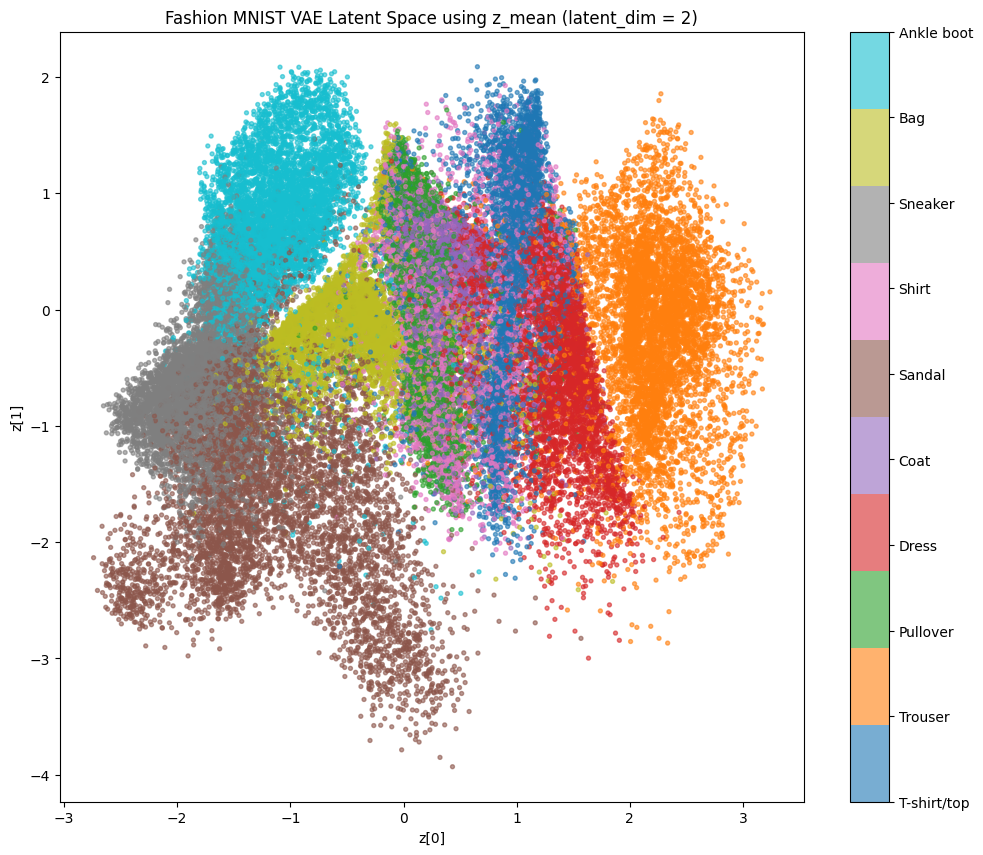

In [17]:
def plot_label_clusters(vae, data, labels):
    # Use z_mean because it gives a stable latent representation
    z_mean, _, _ = vae.encoder.predict(data, verbose=0)

    plt.figure(figsize=(12, 10))

    scatter = plt.scatter(
        z_mean[:, 0],
        z_mean[:, 1],
        c=labels,
        cmap="tab10",
        s=8,
        alpha=0.6
    )

    cbar = plt.colorbar(scatter, ticks=range(10))
    cbar.ax.set_yticklabels([fashion_class_names[i] for i in range(10)])

    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.title("Fashion MNIST VAE Latent Space using z_mean (latent_dim = 2)")
    plt.show()


# Prepare Fashion MNIST data for latent space visualisation
x_train_plot = np.expand_dims(x_train, -1).astype("float32") / 255

plot_label_clusters(vae, x_train_plot, y_train)

### Label Cluster Observation

The direct `z_mean` plot shows that the model has learned some class-related structure. Categories with more distinctive silhouettes, such as Trouser and some footwear classes, occupy relatively clearer regions.

However, substantial overlap remains in the central latent-space regions. T-shirt/top, Pullover, Coat, Shirt, and Dress are especially difficult to separate because their outlines share similar upper-body clothing features.

This indicates that both latent dimensions contain useful information, but a two-dimensional representation does not provide enough separation for all 10 Fashion MNIST classes under the current architecture and training setup.

# 10. t-SNE Analysis of the Latent Representations

t-SNE is applied to a subset of the `z_mean` representations to examine local grouping among Fashion MNIST classes.

Because `latent_dim = 2`, the original `z_mean` representation is already two-dimensional. Therefore, the direct latent-space scatter plot remains the most faithful visualisation of the learned geometry.

The t-SNE plot is used only as a supplementary view of local class neighbourhoods. Distances and cluster separation in t-SNE should not be interpreted as the exact geometry of the original latent space.

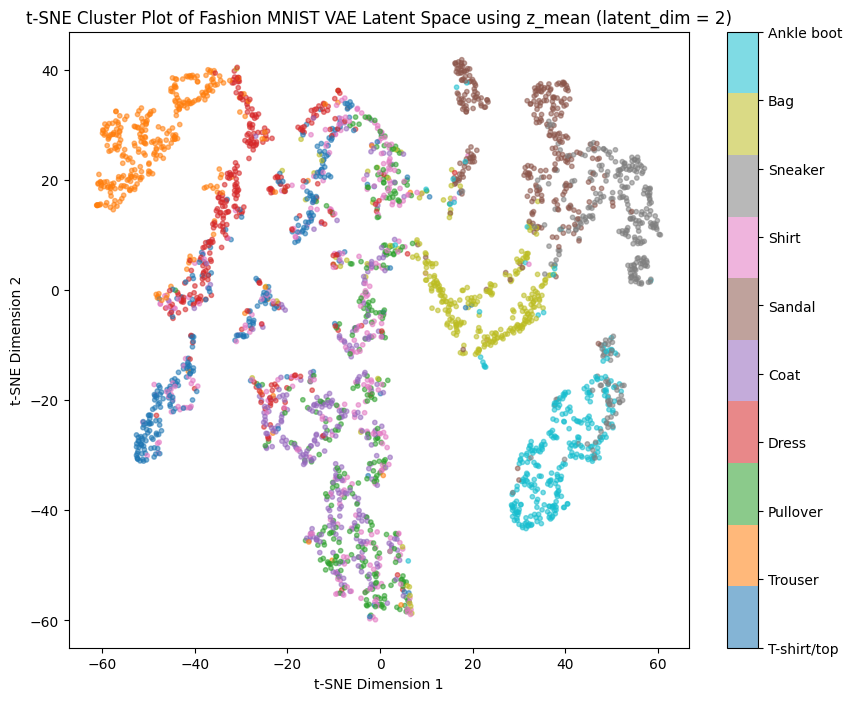

In [18]:
from sklearn.manifold import TSNE
import numpy as np
import matplotlib.pyplot as plt

# Use a subset to reduce computation time
num_samples = 3000

x_subset = x_train_plot[:num_samples]
y_subset = y_train[:num_samples]

# Extract stable latent representations using z_mean
z_mean_subset, _, _ = vae.encoder.predict(x_subset, verbose=0)

# Apply t-SNE to z_mean
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

z_tsne = tsne.fit_transform(z_mean_subset)

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    z_tsne[:, 0],
    z_tsne[:, 1],
    c=y_subset,
    cmap="tab10",
    s=10,
    alpha=0.55
)

cbar = plt.colorbar(scatter, ticks=range(10))
cbar.ax.set_yticklabels([fashion_class_names[i] for i in range(10)])

plt.title("t-SNE Cluster Plot of Fashion MNIST VAE Latent Space using z_mean (latent_dim = 2)")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.show()

### t-SNE Observation

The t-SNE plot forms several local groups. Trouser, Bag, and some footwear categories appear more clearly separated, while upper-body categories such as T-shirt/top, Pullover, Coat, and Shirt remain strongly mixed.

This is consistent with the direct `z_mean` plot: visually distinctive categories are easier to organise, while categories with similar silhouettes share overlapping latent representations.

Because t-SNE can rearrange distances and cluster shapes, this plot supports the local class-overlap analysis but does not replace the original `z_mean` scatter plot.

# 11. Violin Plot of latent_dim = 2

A violin plot is used to observe the distribution of the two latent dimensions, `z[0]` and `z[1]`.

Since this model only uses `latent_dim = 2`, the VAE has only two latent values to represent all 10 Fashion MNIST classes. If the generated images and cluster plots show limited separation, this suggests that two latent neurons may not be enough for Fashion MNIST.

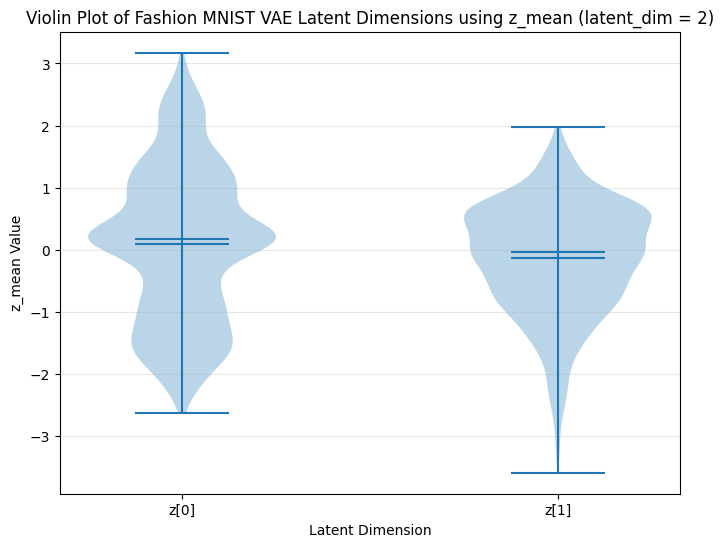

In [20]:
# Violin plot for latent_dim = 2 using z_mean

num_samples = 3000

x_subset = x_train_plot[:num_samples]
y_subset = y_train[:num_samples]

# Extract stable latent representations using z_mean
z_mean_subset, _, _ = vae.encoder.predict(x_subset, verbose=0)

plt.figure(figsize=(8, 6))

data_to_plot = [z_mean_subset[:, i] for i in range(z_mean_subset.shape[1])]

plt.violinplot(
    data_to_plot,
    showmeans=True,
    showmedians=True
)

plt.xticks(
    ticks=np.arange(1, z_mean_subset.shape[1] + 1),
    labels=[f"z[{i}]" for i in range(z_mean_subset.shape[1])]
)

plt.title("Violin Plot of Fashion MNIST VAE Latent Dimensions using z_mean (latent_dim = 2)")
plt.xlabel("Latent Dimension")
plt.ylabel("z_mean Value")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [21]:
for i in range(z_mean_subset.shape[1]):
    print(
        f"z[{i}] mean: {z_mean_subset[:, i].mean():.4f}, "
        f"std: {z_mean_subset[:, i].std():.4f}, "
        f"min: {z_mean_subset[:, i].min():.4f}, "
        f"max: {z_mean_subset[:, i].max():.4f}"
    )

z[0] mean: 0.0865, std: 1.2376, min: -2.6277, max: 3.1724
z[1] mean: -0.1374, std: 0.9139, min: -3.5882, max: 1.9804


### Violin Plot Observation

Both latent dimensions show substantial spread around 0, indicating that `z[0]` and `z[1]` are actively used by the model.

The distribution of `z[0]` is wider than that of `z[1]`, suggesting that the first latent dimension captures slightly more variation in the dataset. Both means remain close to 0, which is consistent with the KL-loss regularisation used by the VAE.

Therefore, the model's limited class separation is not caused by an inactive latent dimension. Instead, both available dimensions are being used, but two values still provide limited capacity for representing the variation among all 10 Fashion MNIST categories.

This conclusion is supported by the generated grid and direct `z_mean` cluster plot rather than by the violin plot alone.

# 12. Save Model Weights

The complete VAE, encoder and decoder weights are saved so that the trained model can be loaded later without repeating the 30-epoch training process.

In [22]:
vae.save_weights("vae_fashion_latent2.weights.h5")
encoder.save_weights("encoder_fashion_latent2.weights.h5")
decoder.save_weights("decoder_fashion_latent2.weights.h5")

# 13. Conclusion

Experiment 1 tested a Fashion MNIST VAE using `latent_dim = 2`.

The model successfully learned a continuous latent space and generated Fashion MNIST-like shapes. Both latent dimensions were actively used, as shown by their non-zero spread in the violin plot.

However, the generated grid contained repeated or unclear outputs, and the direct `z_mean` plot showed substantial overlap among several Fashion MNIST classes. Upper-body clothing categories such as T-shirt/top, Pullover, Coat, and Shirt were especially difficult to separate because of their similar silhouettes.

Therefore, under the current architecture and 30-epoch training setup, `latent_dim = 2` is useful for simple visualisation but appears too restrictive for clear class separation and diverse Fashion MNIST generation.

The next experiment should test larger latent dimensions to determine whether additional capacity improves reconstruction, class representation and generated-image variety.